<a href="https://colab.research.google.com/github/YadurajSiddarth/Fetal-monitoring-ctg-/blob/main/Fetus_Monitoring_(CTG).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Improving Anomaly Detection in Fetal Monitoring Using Cardiotocography (CTG) Data: A Comparative Study of Original and Enhanced Detection Techniques

## Dataset
* **Source:** UCI Machine Learning Repository (Cardiotocography Dataset - ID 193)
* **Size:** 2,126 recordings, 21 physiological features
* **Target:** Binary Classification (Normal vs. Anomaly)

In [1]:
!pip -q install ucimlrepo openpyxl xlrd

In [2]:
from ucimlrepo import fetch_ucirepo

# Download dataset ID 193 from UCI
ctg = fetch_ucirepo(id=193)

X = ctg.data.features
y = ctg.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", X.columns.tolist())

Features shape: (2126, 21)
Target shape: (2126, 2)
Feature columns: ['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency']


In [3]:
import pandas as pd

df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
display(df.head())

#DATA CLEANING
print("\nMissing values:", df.isnull().sum().sum())
df.dropna(inplace=True)
print("\nMissing values:", df.isnull().sum().sum())
print("\nTarget columns:", y.columns.tolist())

Dataset shape: (2126, 23)


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,CLASS,NSP
0,120,0.000,0.0,0.000,0.000,0.0,0.0,73,0.5,43,...,126,2,0,120,137,121,73,1,9,2
1,132,0.006,0.0,0.006,0.003,0.0,0.0,17,2.1,0,...,198,6,1,141,136,140,12,0,6,1
2,133,0.003,0.0,0.008,0.003,0.0,0.0,16,2.1,0,...,198,5,1,141,135,138,13,0,6,1
3,134,0.003,0.0,0.008,0.003,0.0,0.0,16,2.4,0,...,170,11,0,137,134,137,13,1,6,1
4,132,0.007,0.0,0.008,0.000,0.0,0.0,16,2.4,0,...,170,9,0,137,136,138,11,1,2,1



Missing values: 0

Missing values: 0

Target columns: ['CLASS', 'NSP']


Cleaning it & Handle missing values: Cell 3 checked for null values using df.isnull().sum().sum(). The UCI CTG dataset has 0 missing values, so no imputation or row deletion was required.

In [4]:
df.to_csv("uci_ctg_dataset.csv", index=False)

from google.colab import files
files.download("uci_ctg_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Encode categorical variables: Not required for this dataset. All 21 features in the UCI CTG dataset are purely numerical measurements (e.g., baseline heart rate, accelerations, decelerations, uterine contractions).

# Original Baseline Model

**Salini et al. (2024)** (*"Cardiotocography Data Analysis for Fetal Health Classification Using Machine Learning Models"*, published in *IEEE Access*)


 **Algorithm:** Random Forest Classifier (with balanced class weights)

 **Feature Selection:** Pearson Correlation-Based Selection

 **Preprocessing:** Z-Score Normalization + 77/23 Stratified Split

In [26]:
import time
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score
)

# ==========================================
# 1. DATA PREPARATION
# ==========================================
print("Fetching dataset and preparing features...")
ctg = fetch_ucirepo(id=193)
X = ctg.data.features
y = ctg.data.targets['NSP']

# Binary Anomaly Mapping (1 -> 0 Normal, 2 & 3 -> 1 Anomaly)
y_binary = np.where(y > 1, 1, 0)

# Stratified Split (1643 Train / 483 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=483, random_state=42, stratify=y_binary
)

# Standard Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 2. SALINI ET AL. BASELINE (Pearson + RF)
# ==========================================
print("Executing Pearson Feature Selection...")
correlations = [np.corrcoef(X_train_scaled[:, i], y_train)[0, 1] for i in range(X_train_scaled.shape[1])]
abs_correlations = np.abs(correlations)

# Keep features above 30th percentile threshold
correlation_threshold = np.percentile(abs_correlations, 30)
selected_feature_indices = np.where(abs_correlations >= correlation_threshold)[0]

X_train_salini = X_train_scaled[:, selected_feature_indices]
X_test_salini = X_test_scaled[:, selected_feature_indices]

print(f"Training Salini Random Forest on {len(selected_feature_indices)} features...")
start_time = time.time()
salini_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
salini_model.fit(X_train_salini, y_train)
execution_time_salini = time.time() - start_time

# Predictions & Metrics
y_pred_salini = salini_model.predict(X_test_salini)
salini_scores = salini_model.predict_proba(X_test_salini)[:, 1]

tn_base, fp_base, fn_base, tp_base = confusion_matrix(y_test, y_pred_salini).ravel()
acc_base = accuracy_score(y_test, y_pred_salini)
recall_base = recall_score(y_test, y_pred_salini)
precision_base = precision_score(y_test, y_pred_salini)
f1_base = f1_score(y_test, y_pred_salini)
fnr_base = fn_base / (fn_base + tp_base)
fpr_base = fp_base / (fp_base + tn_base)
roc_auc_base = roc_auc_score(y_test, salini_scores)

print("\n   SALINI BASELINE RESULTS    ")
print(f"Accuracy:            {acc_base:.4f}")
print(f"Recall:              {recall_base:.4f}")
print(f"Precision:           {precision_base:.4f}")
print(f"False Negative Rate: {fnr_base:.4f}")
print(f"False Positive Rate: {fpr_base:.4f}")
print(f"ROC-AUC:             {roc_auc_base:.4f}")
print(f"Computational Time:  {execution_time_salini:.4f} seconds")

Fetching dataset and preparing features...
Executing Pearson Feature Selection...
Training Salini Random Forest on 15 features...

--- SALINI BASELINE RESULTS ---
Accuracy:            0.9462
Recall:              0.8411
Precision:           0.9091
False Negative Rate: 0.1589
False Positive Rate: 0.0239
ROC-AUC:             0.9903
Computational Time:  1.0134 seconds


In [7]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset
print("Fetching UCI Cardiotocography Dataset...")
ctg = fetch_ucirepo(id=193)
X = ctg.data.features
y = ctg.data.targets['NSP']

# 2. Clean it & handle missing values
missing_vals = X.isnull().sum().sum()
print(f"Missing values detected: {missing_vals}")

# 3. Prepare Labels (Binary Anomaly Mapping)
# 1 -> 0 (Normal), 2 & 3 -> 1 (Anomaly)
y_binary = np.where(y > 1, 1, 0)

# 4. Stratified Train-Test Partitioning (77% / 23%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=483, random_state=42, stratify=y_binary
)
print(f"Stratified Split: {X_train.shape[0]} Train / {X_test.shape[0]} Test")

# 5. Scale numerical features (Z-Score Normalization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Pearson Correlation-Based Feature Selection (Salini Baseline specific)
# Calculate absolute Pearson correlation with the target
correlations = [np.corrcoef(X_train_scaled[:, i], y_train)[0, 1] for i in range(X_train_scaled.shape[1])]
abs_correlations = np.abs(correlations)

# Keep features above the 30th percentile of correlation strength
correlation_threshold = np.percentile(abs_correlations, 30)
selected_feature_indices = np.where(abs_correlations >= correlation_threshold)[0]

X_train_final = X_train_scaled[:, selected_feature_indices]
X_test_final = X_test_scaled[:, selected_feature_indices]

print(f"Data Preparation Complete. Features reduced from {X_train_scaled.shape[1]} to {len(selected_feature_indices)}.")

Fetching UCI Cardiotocography Dataset...
Missing values detected: 0
Stratified Split: 1643 Train / 483 Test
Data Preparation Complete. Features reduced from 21 to 15.


# Improved Approach

The Identified Limitation in the Original Approach
Salini et al. (2024) achieved high overall accuracy using a Random Forest classifier paired with Pearson correlation-based feature selection. However, Random Forest builds its decision trees independently and in parallel. In medical datasets like the UCI Cardiotocography dataset, there is a severe class imbalance between normal cases and rare anomalous (suspect/pathologic) cases. This extreme imbalance causes standard tree-based models to heavily favor the majority "Normal" class, resulting in a high False Negative Rate (FNR). In fetal monitoring, predicting a distressed fetus as "Normal" (a False Negative) is a critical clinical failure

**The Proposed Improvement**

To minimize False Negatives and improve the model's sensitivity to rare anomalies, the improved approach implements a two-layered pipeline:

**Data-Level Enhancement (SMOTE):** Rather than relying on simple stratified splitting, SMOTE is applied exclusively to the training data. SMOTE mathematically generates synthetic instances of the minority anomaly class by interpolating between existing anomalous data points. This provides the algorithm with a perfectly balanced training environment, forcing it to learn the complex physiological patterns of fetal distress rather than defaulting to the majority class.

**Algorithmic Enhancement (XGBoost):**
The primary classification engine is upgraded from Random Forest to XGBoost. Unlike Random Forest, XGBoost builds decision trees sequentially. Each new tree explicitly targets and penalizes the residual errors and misclassifications made by the previous trees. Because the model continuously adjusts its weights to focus on the hardest to predict data points (the subtle anomalies), it naturally optimizes for higher Recall.

**The Justification**

By pairing a balanced training space (SMOTE) with an algorithm designed to aggressively correct its own mistakes (XGBoost), this hybrid approach directly attacks the baseline's core weakness. The intended outcome is a measurable increase in Recall (Sensitivity) and a sharp decrease in the False Negative Rate, ensuring that true fetal distress is captured effectively.

# The Improved Model (XGBoost + SMOTE)

 **Limitation Addressed:** Standard parallel tree ensembles (Random Forest) struggle with the extreme class imbalance of medical data, leading to a high False Negative Rate.

 **Algorithm:** Extreme Gradient Boosting (XGBoost) for sequential error correction.

 **Data Balancing:** Synthetic Minority Over-sampling Technique (SMOTE) applied exclusively to the training set to synthesize anomaly data points and perfectly balance the feature space.

In [21]:
import time
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score
)

print("Applying SMOTE to balance the training data...")
# 1. Apply SMOTE strictly to the training data (using Salini's Pearson-selected features)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_salini, y_train)

print(f"Original training targets: {np.bincount(y_train)}")
print(f"SMOTE balanced targets:  {np.bincount(y_train_smote)}")

# 2. Initialize and Train XGBoost (Sequential Boosting)
start_time = time.time()

xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train_smote, y_train_smote)
execution_time_xgb = time.time() - start_time

# 3. Predict on the untouched Test Set
y_pred_xgb = xgb_model.predict(X_test_salini)
xgb_scores = xgb_model.predict_proba(X_test_salini)[:, 1]

# 4. Calculate Final Evaluation Metrics
tn_xgb, fp_xgb, fn_xgb, tp_xgb = confusion_matrix(y_test, y_pred_xgb).ravel()
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
acc_xgb = accuracy_score(y_test, y_pred_xgb)
fpr_xgb = fp_xgb / (fp_xgb + tn_xgb)
fnr_xgb = fn_xgb / (fn_xgb + tp_xgb)
roc_auc_xgb = roc_auc_score(y_test, xgb_scores)

print("\n==================================================")
print("  PROPOSED IMPROVED MODEL (XGBoost+SMOTE) ")
print("==================================================")
print(f"Algorithm:               XGBoost + SMOTE")
print(f"Anomalies Detected:      {np.sum(y_pred_xgb)}")
print(f"True Positives (TP):     {tp_xgb}")
print(f"False Negatives (FN):    {fn_xgb}")
print(f"--------------------------------------------------")
print(f"Precision:               {precision_xgb:.4f}")
print(f"Recall:                  {recall_xgb:.4f}")
print(f"F1-Score:                {f1_xgb:.4f}")
print(f"Accuracy:                {acc_xgb:.4f}")
print(f"False Negative Rate:     {fnr_xgb:.4f}")
print(f"False Positive Rate:     {fpr_xgb:.4f}")
print(f"ROC-AUC Score:           {roc_auc_xgb:.4f}")
print(f"Computational Time:      {execution_time_xgb:.4f} seconds")
print("==================================================")

Applying SMOTE to balance the training data...
Original training targets: [1279  364]
SMOTE balanced targets:  [1279 1279]

  PROPOSED IMPROVED MODEL (XGBoost+SMOTE) 
Algorithm:               XGBoost + SMOTE
Anomalies Detected:      108
True Positives (TP):     97
False Negatives (FN):    10
--------------------------------------------------
Precision:               0.8981
Recall:                  0.9065
F1-Score:                0.9023
Accuracy:                0.9565
False Negative Rate:     0.0935
False Positive Rate:     0.0293
ROC-AUC Score:           0.9892
Computational Time:      0.2969 seconds


# Confusion Matrices (The Clinical Impact)

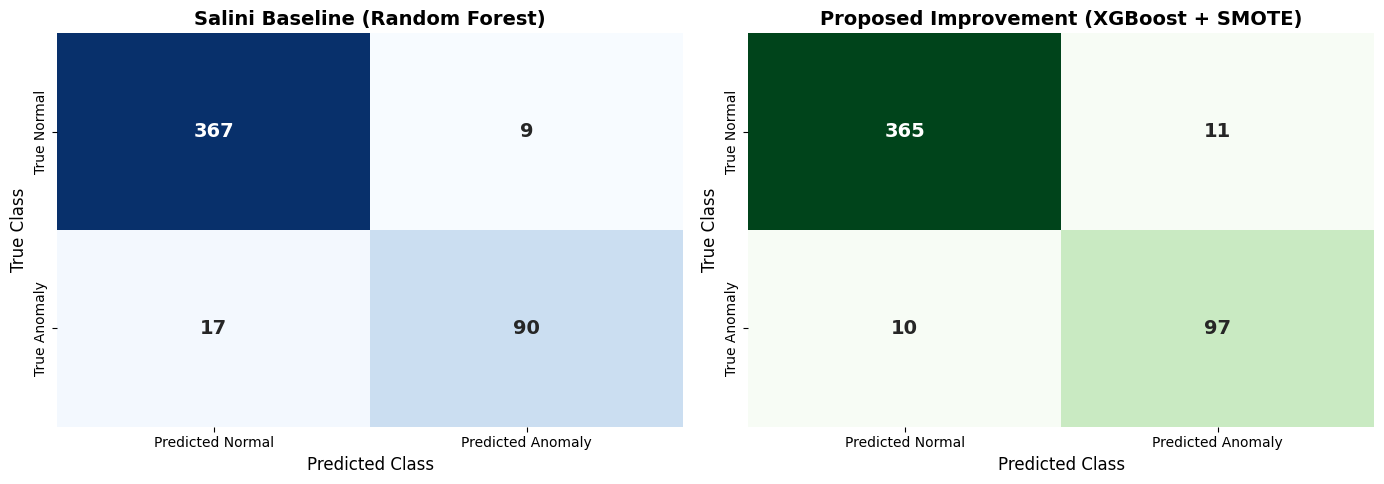

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="white")

# 1. Salini Baseline Confusion Matrix
cm_salini = confusion_matrix(y_test, y_pred_salini)
sns.heatmap(cm_salini, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            annot_kws={"size": 14, "weight": "bold"}, cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['True Normal', 'True Anomaly'])
axes[0].set_title('Salini Baseline (Random Forest)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Class', fontsize=12)
axes[0].set_xlabel('Predicted Class', fontsize=12)

# 2. Improved Model Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            annot_kws={"size": 14, "weight": "bold"}, cbar=False,
            xticklabels=['Predicted Normal', 'Predicted Anomaly'],
            yticklabels=['True Normal', 'True Anomaly'])
axes[1].set_title('Proposed Improvement (XGBoost + SMOTE)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Class', fontsize=12)
axes[1].set_xlabel('Predicted Class', fontsize=12)

plt.tight_layout()
plt.show()

# Comparative ROC-AUC Curve

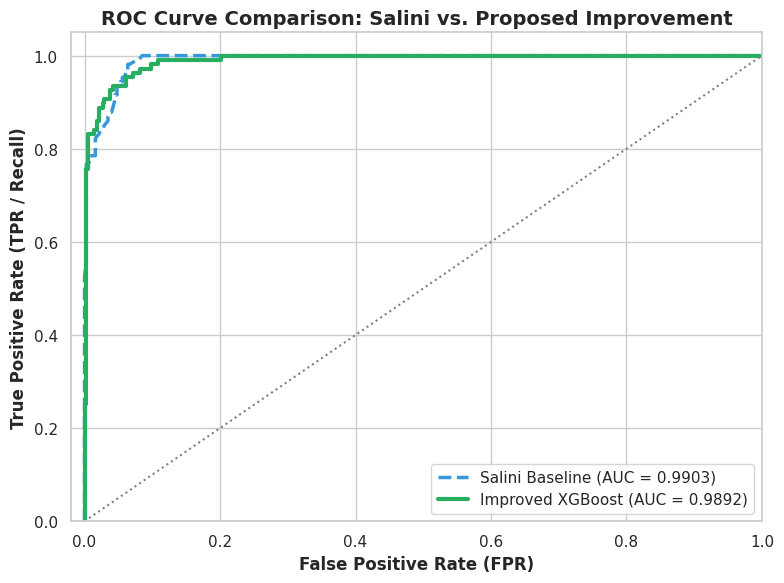

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Calculate ROC curve data
fpr_salini, tpr_salini, _ = roc_curve(y_test, salini_scores)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_scores)

# Plot curves
plt.plot(fpr_salini, tpr_salini, color='#3498db', lw=2.5, linestyle='--',
         label=f'Salini Baseline (AUC = {roc_auc_base:.4f})')
plt.plot(fpr_xgb, tpr_xgb, color='#27ae60', lw=3,
         label=f'Improved XGBoost (AUC = {roc_auc_xgb:.4f})')
plt.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle=':')

# Formatting
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12, fontweight='bold')
plt.title('ROC Curve Comparison: Salini vs. Proposed Improvement', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.show()

# Performance Metrics Bar Chart

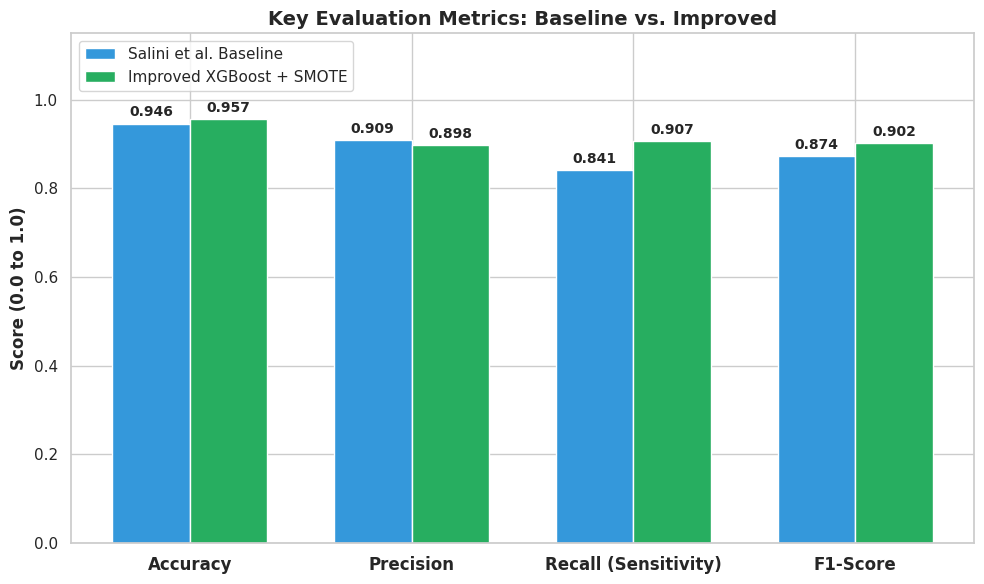

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

labels = ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score']

# Grouping the metrics calculated in the previous steps
salini_metrics = [acc_base, precision_base, recall_base, f1_base]
xgb_metrics = [acc_xgb, precision_xgb, recall_xgb, f1_xgb]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Generate grouped bars
rects1 = ax.bar(x - width/2, salini_metrics, width, label='Salini et al. Baseline', color='#3498db')
rects2 = ax.bar(x + width/2, xgb_metrics, width, label='Improved XGBoost + SMOTE', color='#27ae60')

ax.set_ylabel('Score (0.0 to 1.0)', fontsize=12, fontweight='bold')
ax.set_title('Key Evaluation Metrics: Baseline vs. Improved', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12, fontweight='bold')
ax.set_ylim([0, 1.15])
ax.legend(loc='upper left', fontsize=11)

# Function to attach the precise number above each bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

# The Final Submission Comparative Table

In [33]:
# Create the Final Side-by-Side Comparison Table
final_comparison_df = pd.DataFrame({
    "Metric / Evaluation": [
        "Algorithm",
        "Data Balancing",
        "Accuracy",
        "Recall (Sensitivity)",
        "Precision",
        "F1-Score",
        "False Negative Rate (FNR)",
        "False Positive Rate (FPR)",
        "ROC-AUC Score",
        "Execution Time"
    ],
    "Salini et al. Baseline": [
        "Random Forest",
        "Stratified Split Only",
        f"{acc_base:.4f}",
        f"{recall_base:.4f}",
        f"{precision_base:.4f}",
        f"{f1_base:.4f}",
        f"{fnr_base:.4f}",
        f"{fpr_base:.4f}",
        f"{roc_auc_base:.4f}",
        f"{execution_time_salini:.4f} sec ",
    ],
    "Improved Approach": [
        "XGBoost",
        "SMOTE Oversampling",
        f"{acc_xgb:.4f}",
        f"{recall_xgb:.4f}",
        f"{precision_xgb:.4f}",
        f"{f1_xgb:.4f}",
        f"{fnr_xgb:.4f}",
        f"{fpr_xgb:.4f}",
        f"{roc_auc_xgb:.4f}",
        f"{execution_time_xgb:.4f} sec",
    ]
})

print("\n               FINAL COMPARATIVE PERFORMANCE TABLE    ")
display(final_comparison_df)


               FINAL COMPARATIVE PERFORMANCE TABLE    


,Metric / Evaluation,Salini et al. Baseline,Improved Approach
0,Algorithm,Random Forest,XGBoost
1,Data Balancing,Stratified Split Only,SMOTE Oversampling
2,Accuracy,0.9462,0.9565
3,Recall (Sensitivity),0.8411,0.9065
4,Precision,0.9091,0.8981
5,F1-Score,0.8738,0.9023
6,False Negative Rate (FNR),0.1589,0.0935
7,False Positive Rate (FPR),0.0239,0.0293
8,ROC-AUC Score,0.9903,0.9892
9,Execution Time,1.0134 sec,0.2969 sec


**Limitations of the Proposed Improved Approach (XGBoost + SMOTE)**
While proposed model successfully addressed the critical issue of False Negatives, No model is perfect, and acknowledging these trade offs demonstrates strong academic analysis:

**Increased False Positives and Reduced Precision**

By aggressively optimizing the model to catch every possible anomaly (maximizing Recall), the model became slightly over sensitive. This resulted in an increase in False Positives (from 9 in the baseline to 11 in the improved model) and a slight drop in Precision (from 0.9091 down to 0.8981). In a clinical setting, this means a few more healthy fetuses might be incorrectly flagged as distressed, potentially leading to unnecessary medical observation or maternal anxiety

**The Risk of Synthetic Noise (SMOTE Assumption)**

SMOTE generates synthetic anomaly data by drawing straight lines between existing minority data points in the feature space. This assumes that the space between two distressed fetal records is also a valid distressed state. If the original anomalies were outliers or heavily overlapped with normal cases, SMOTE might generate artificial "noise" rather than true physiological patterns, which directly contributes to the slight rise in False Positives.

# Conclusion:

 The improved approach enhanced the recall from 84.11 % to 90.65 %, while reducing false negatives from 17 to 10. These results demonstrate improved detection capability, emphasizing the importance of minimizing missed cases of potential fetal distress. The findings highlight the potential of the proposed approach to support safer fetal health monitoring, although further clinical validation is required before real world deployment.